# Montreal Crime After COVID: Trends, Recovery and Hotspots (2015 - 2025)
*Nada Afiri*

## Why this project
The Montreal Police Department (SPVM) publishes every reported criminal act since 2015. Eleven complete years let us ask a question that a short window cannot: **what happened to crime in Montreal after the COVID-19 shock, and has it gone back to its pre-pandemic level?**

I organize the analysis around six questions:

1. Compared with 2019, which crime types are higher or lower in 2025?
2. How large is the vehicle theft surge, when did it start, and when do these thefts happen?
3. Which parts of the island account for the largest increases in vehicle theft?
4. Do crimes follow different weekly and night-time patterns, and have they shifted?
5. Are incidents concentrated in a small number of locations, and is that changing?
6. How does 2026 so far compare with the same months of earlier years?

## Data
Source: [Montreal Open Data Portal, "Actes criminels"](https://donnees.montreal.ca/dataset/actes-criminels), published by the SPVM. Each row is one incident reported to the police, with:

* **category** (translated to English below): burglary, vehicle contents or parts theft, vehicle theft, mischief (méfait), robbery, offenses causing death (which includes manslaughter and criminal negligence, not only murder);
* **date** the incident was reported and **time of day** (day, evening, night);
* **PDQ**, the neighborhood police station responsible for the area;
* **latitude and longitude**, moved to the nearest intersection by the SPVM for privacy.

Two things to keep in mind throughout: the data counts incidents **reported to the police**, and about a sixth of the rows have no usable location.

## Setup

In [1]:
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import display

from crime_utils import (ALL_CATEGORIES, MAIN_CATEGORIES, WEEKDAYS, TIMES_OF_DAY,
                         load_crimes, data_quality, quality_report, yearly_table, index_to_baseline,
                         cell_changes, change_map, concentration_by_year,
                         last_complete_month, year_to_date)

pio.templates.default = "plotly_white"

BASE_YEAR = 2019        # last "normal" year before COVID-19
LAST_FULL_YEAR = 2025   # 2026 is only used in the year-to-date comparison

Download the csv from the portal and save it as `data/actes-criminels.csv` (the `data/` folder is ignored by git).

In [2]:
df = load_crimes("data/actes-criminels.csv")
data_quality(df)

,Value
Records,"365,643"
First date,2015-01-01
Last date,2026-11-16
Without usable location,16.7%
Without PDQ,0.00%
Without time of day,0.00%


### Data quality check
Before analysing anything, here is what the cleaning keeps, drops or flags in the raw file. Nothing is removed silently: rows are only dropped when the date or the category cannot be read, and exact duplicate rows are counted but kept, because the file has no incident identifier and two different incidents can share the same date, category and intersection.

In [3]:
quality_report("data/actes-criminels.csv")

,Rows,% of raw rows
Check,,
Raw rows,365643,100.00
Invalid dates (dropped),0,0.00
Unrecognised categories (dropped),0,0.00
Rows kept after cleaning,365643,100.00
"Exact duplicate rows (kept, counted only)",11307,3.09
"Missing coordinates (kept, no map position)",61098,16.71
"Coordinates outside the Montreal box (kept, no map position)",0,0.00
Missing PDQ (kept),8,0.00
Unrecognised time of day (kept),0,0.00


In [4]:
full = df[df["YEAR"] <= LAST_FULL_YEAR]       # complete years only
yearly = yearly_table(full)
yearly

CATEGORY,Vehicle contents or parts theft,Burglary,Mischief,Vehicle theft,Robbery,Offenses causing death
YEAR,,,,,,
2015,10915,9796,8356,4418,2097,27
2016,10209,9797,7405,4352,1974,23
2017,9556,9197,7302,4732,1851,26
2018,8666,7429,6432,4237,1592,31
2019,8018,6987,6171,4170,1785,24
2020,7403,6057,5869,4706,1399,26
2021,7962,5111,5820,6440,1456,34
2022,9150,6292,6070,9377,1699,37
2023,8198,6541,6682,11528,1992,25


## 1. Where is each crime type compared with 2019?
Raw counts hide the story because the categories have very different sizes. I rescale every category so that **2019 = 100**: a value of 130 means 30% more incidents than in 2019. Offenses causing death are left out of this chart (about 30 per year, too few for percentages) and are reported in the table below.

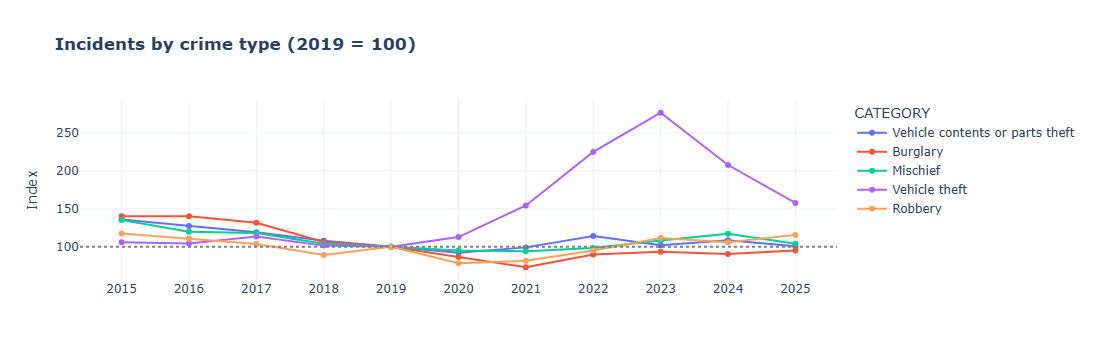

In [5]:
index = index_to_baseline(yearly[MAIN_CATEGORIES], BASE_YEAR)
long_index = index.reset_index().melt(id_vars="YEAR", var_name="CATEGORY", value_name="INDEX")

fig = px.line(long_index, x="YEAR", y="INDEX", color="CATEGORY", markers=True,
              title="<b>Incidents by crime type (2019 = 100)</b>")
fig.add_hline(y=100, line_dash="dot", line_color="grey")
fig.update_xaxes(dtick=1, title=None)
fig.update_yaxes(title="Index")
fig.show()

In [6]:
last = yearly.loc[LAST_FULL_YEAR]
base = yearly.loc[BASE_YEAR]
comparison = pd.DataFrame({
    str(BASE_YEAR): base,
    str(LAST_FULL_YEAR): last,
    "Change (%)": ((last / base - 1) * 100).round(1),
}).sort_values("Change (%)", ascending=False)
comparison

,2019,2025,Change (%)
CATEGORY,,,
Offenses causing death,24,39,62.5
Vehicle theft,4170,6579,57.8
Robbery,1785,2066,15.7
Mischief,6171,6416,4.0
Vehicle contents or parts theft,8018,8076,0.7
Burglary,6987,6656,-4.7


**How to read it.** Categories above the dotted line are higher than before the pandemic; those below it have not come back to their 2019 level. Compare the lockdown year (2020) with the following years to separate the temporary COVID effect from the longer trend.

## 2. The vehicle theft surge
Vehicle theft is the category that moves differently from the others. Here is its monthly evolution, smoothed with a 12-month rolling average to show the trend beyond seasonal noise.

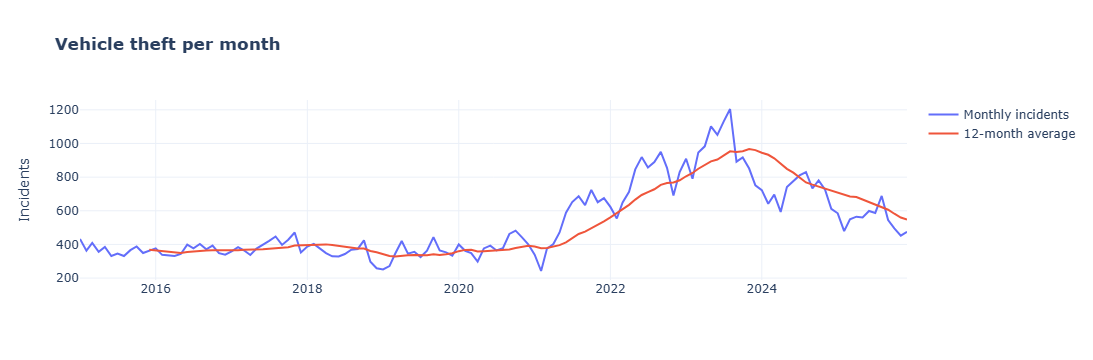

Peak year: 2023 (11,528 incidents, +176% vs 2019)
Busiest month: August 2023


In [7]:
vt = full[full["CATEGORY"] == "Vehicle theft"]
monthly_vt = (vt.groupby(pd.Grouper(key="DATE", freq="MS")).size()
                .rename("Monthly incidents").to_frame())
monthly_vt["12-month average"] = monthly_vt["Monthly incidents"].rolling(12).mean()

fig = px.line(monthly_vt, y=["Monthly incidents", "12-month average"],
              title="<b>Vehicle theft per month</b>")
fig.update_layout(legend_title_text="", xaxis_title=None, yaxis_title="Incidents")
fig.show()

peak_year = int(yearly["Vehicle theft"].idxmax())
peak_month = monthly_vt["Monthly incidents"].idxmax()
print("Peak year: {} ({:,} incidents, {:+.0%} vs {})".format(
    peak_year, yearly.loc[peak_year, "Vehicle theft"],
    yearly.loc[peak_year, "Vehicle theft"] / yearly.loc[BASE_YEAR, "Vehicle theft"] - 1, BASE_YEAR))
print("Busiest month:", peak_month.strftime("%B %Y"))

Do these thefts happen at a different time of day than before?

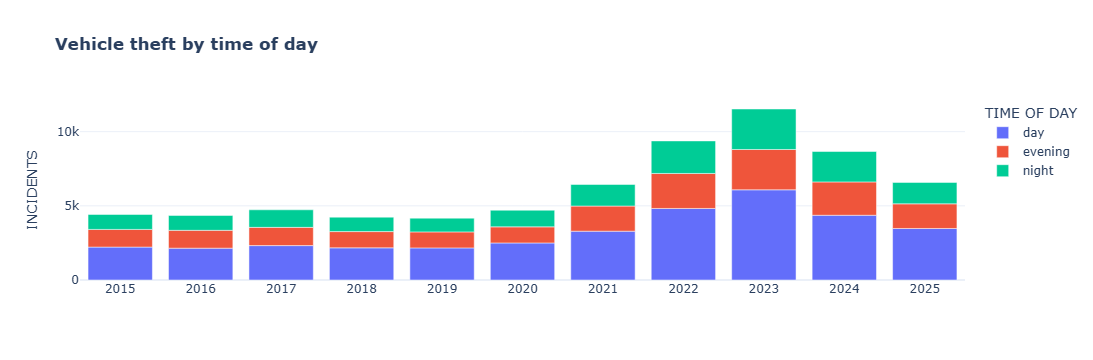

In [8]:
tod = (pd.crosstab(vt["YEAR"], vt["TIME_OF_DAY"])[TIMES_OF_DAY]
         .reset_index().melt(id_vars="YEAR", var_name="TIME OF DAY", value_name="INCIDENTS"))

fig = px.bar(tod, x="YEAR", y="INCIDENTS", color="TIME OF DAY",
             category_orders={"TIME OF DAY": TIMES_OF_DAY},
             title="<b>Vehicle theft by time of day</b>")
fig.update_xaxes(dtick=1, title=None)
fig.show()

## 3. Where did vehicle theft increase the most?
Police station (PDQ) boundaries were reorganized during the period (the number of stations drops from 34 to 29), so comparing PDQs year to year would be misleading. Instead I divide the island into a regular grid of cells of about 1.1 km by 0.8 km and compare the peak year with 2019. Each cell is labeled with its coordinates and the PDQ that most often covers it.

In [9]:
pdq_per_year = full.groupby("YEAR")["PDQ"].nunique()
print("Number of PDQ: {} in {}, {} in {}".format(
    pdq_per_year.iloc[0], pdq_per_year.index[0],
    pdq_per_year.iloc[-1], pdq_per_year.index[-1]))
pdq_per_year.to_frame("PDQ count").T

Number of PDQ: 34 in 2015, 29 in 2025


YEAR,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
PDQ count,34,34,34,34,33,32,32,31,31,31,29


,LABEL,2019,2023,CHANGE
0,"45.50, -73.56 (PDQ 21)",22,255,233
1,"45.46, -73.83 (PDQ 5)",43,241,198
2,"45.49, -73.58 (PDQ 20)",9,189,180
3,"45.50, -73.58 (PDQ 20)",33,195,162
4,"45.51, -73.58 (PDQ 38)",12,166,154
5,"45.50, -73.57 (PDQ 20)",13,165,152
6,"45.52, -73.59 (PDQ 38)",13,133,120
7,"45.51, -73.57 (PDQ 21)",26,139,113
8,"45.49, -73.59 (PDQ 12)",8,113,105
9,"45.45, -73.75 (PDQ 5)",17,117,100


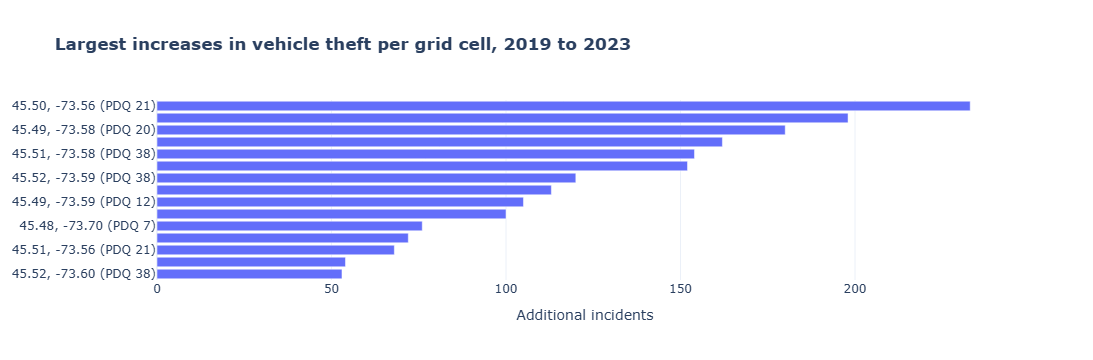

In [10]:
changes = cell_changes(full, "Vehicle theft", BASE_YEAR, peak_year, top=15)
display(changes[["LABEL", BASE_YEAR, peak_year, "CHANGE"]])

fig = px.bar(changes.iloc[::-1], x="CHANGE", y="LABEL", orientation="h",
             title="<b>Largest increases in vehicle theft per grid cell, {} to {}</b>".format(BASE_YEAR, peak_year))
fig.update_yaxes(title=None, type="category")
fig.update_xaxes(title="Additional incidents")
fig.show()

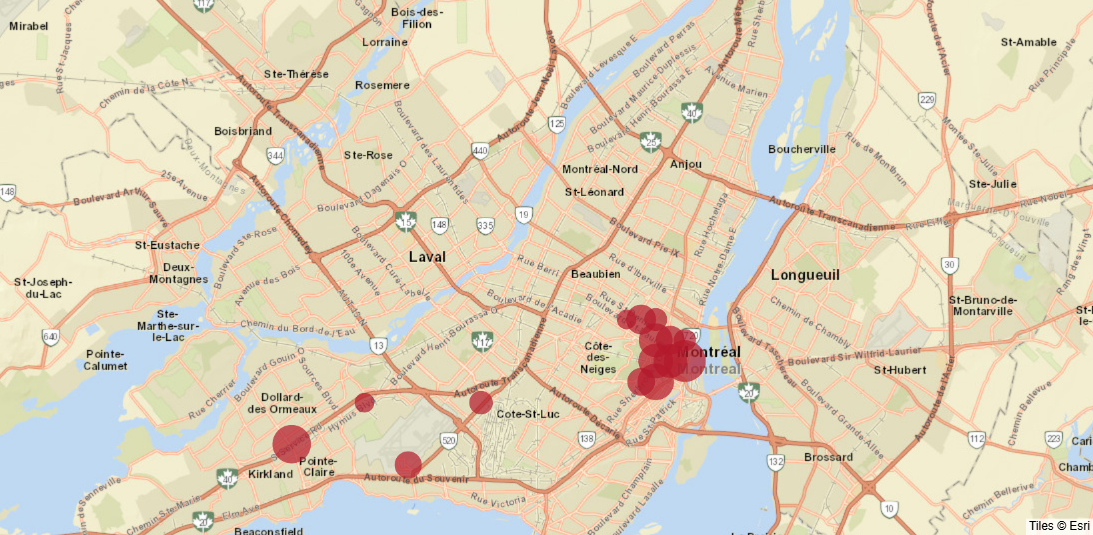

In [11]:
change_map(changes)   # saves the standalone map to map_hotspots.html

changes["LAT_C"] = changes["CELL_LAT"] + 0.005
changes["LON_C"] = changes["CELL_LON"] + 0.005

fig = px.scatter_map(
    changes, lat="LAT_C", lon="LON_C", size="CHANGE", hover_name="LABEL",
    size_max=30, zoom=10, height=520, color_discrete_sequence=["#b2182b"],
)
fig.update_layout(
    map_style="white-bg",
    map_layers=[{
        "below": "traces", "sourcetype": "raster",
        "source": ["https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"],
        "sourceattribution": "Tiles © Esri",
    }],
    map_center=dict(lat=45.55, lon=-73.65),   # center it on the Island of Montreal
    map_zoom=10,
    margin=dict(l=0, r=0, t=0, b=0),
)
fig.show()

*Circles are centered on each cell and sized by the increase. Only incidents with a usable location are counted, so the real increase is larger than what the map shows.*

## 4. When do crimes happen?
For each crime type, the share of its incidents falling on each weekday shows which ones are tied to the working week and which to the weekend.

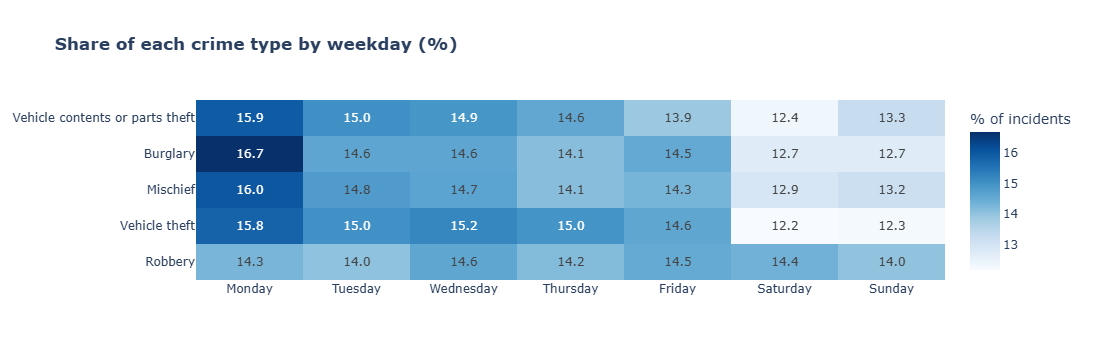

In [12]:
week = full.pivot_table(index="CATEGORY", columns="WEEKDAY", values="DATE",
                        aggfunc="count", observed=False)[WEEKDAYS]
week = week.div(week.sum(axis=1), axis=0).mul(100).loc[MAIN_CATEGORIES]

fig = px.imshow(week, text_auto=".1f", aspect="auto", color_continuous_scale="Blues",
                labels=dict(x="", y="", color="% of incidents"),
                title="<b>Share of each crime type by weekday (%)</b>")
fig.show()

Vehicle theft behaves differently at the weekend. The table compares its weekday shares before the pandemic (2015–2019) and in the recent period (2022–2025); 2020–2021 are left out because of the COVID-19 lockdowns.

In [13]:
vt_week = vt.assign(PERIOD=vt["YEAR"].map(lambda y: "2015-2019" if y <= 2019
                                          else ("2022-2025" if y >= 2022 else None)))
vt_week = vt_week.dropna(subset=["PERIOD"])
share = (pd.crosstab(vt_week["PERIOD"], vt_week["WEEKDAY"], normalize="index")
           .mul(100).round(1)[WEEKDAYS])
share

WEEKDAY,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
PERIOD,,,,,,,
2015-2019,15.7,15.6,16.2,15.8,15.0,11.4,10.2
2022-2025,15.6,14.3,14.1,14.0,14.4,13.3,14.3


A more recent question is whether crime has moved toward the night. Here is the share of each crime type reported at night, by year.

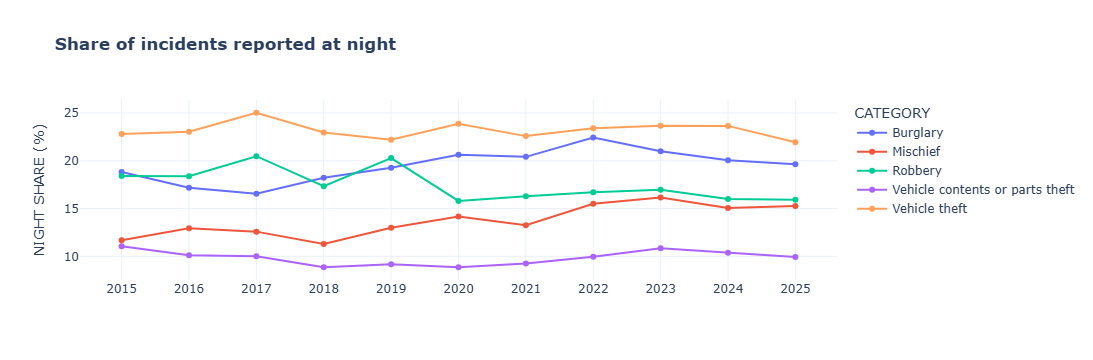

In [14]:
night = (pd.crosstab([full["YEAR"], full["CATEGORY"]], full["TIME_OF_DAY"], normalize="index")["night"]
           .mul(100).rename("NIGHT SHARE (%)").reset_index())
night = night[night["CATEGORY"].isin(MAIN_CATEGORIES)]

fig = px.line(night, x="YEAR", y="NIGHT SHARE (%)", color="CATEGORY", markers=True,
              title="<b>Share of incidents reported at night</b>")
fig.update_xaxes(dtick=1, title=None)
fig.show()

## 5. Are incidents concentrated in a few places?
If a small share of intersections concentrates a large share of incidents, targeted prevention is more effective. For each year I compute the share of all located incidents that occur at the busiest 1% and 5% of intersections.

,LOCATIONS,TOP 1% OF LOCATIONS,TOP 5% OF LOCATIONS
YEAR,,,
2015,10326,8.4,23.2
2016,10148,8.2,23.2
2017,9999,8.0,22.3
2018,9458,8.2,22.7
2019,9162,7.8,21.9
2020,9047,7.3,20.9
2021,9315,8.2,21.9
2022,10007,9.6,24.1
2023,10077,11.1,26.6


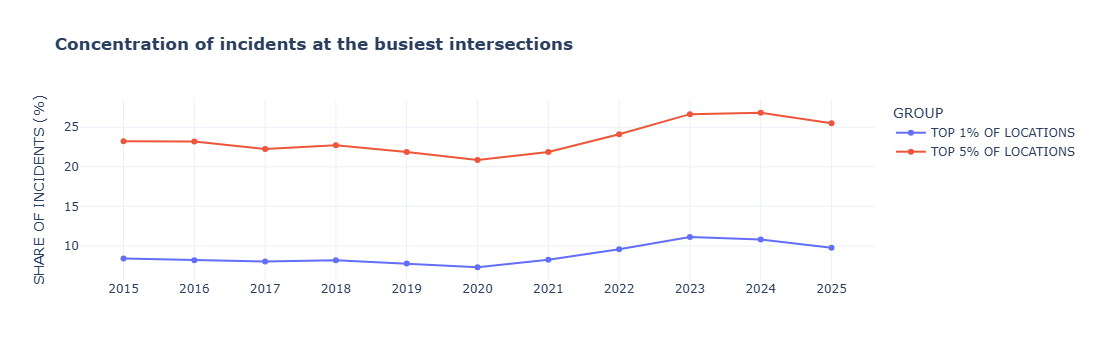

In [15]:
conc = concentration_by_year(full)
display(conc.round(1))

long_conc = (conc.drop(columns="LOCATIONS").reset_index()
                 .melt(id_vars="YEAR", var_name="GROUP", value_name="SHARE OF INCIDENTS (%)"))
fig = px.line(long_conc, x="YEAR", y="SHARE OF INCIDENTS (%)", color="GROUP", markers=True,
              title="<b>Concentration of incidents at the busiest intersections</b>")
fig.update_xaxes(dtick=1, title=None)
fig.show()

## 6. 2026 so far
The file stops in mid-November 2026, so a full-year comparison is impossible. I compare the same window (January to the last complete month) for every year.

Window used: January to October of each year


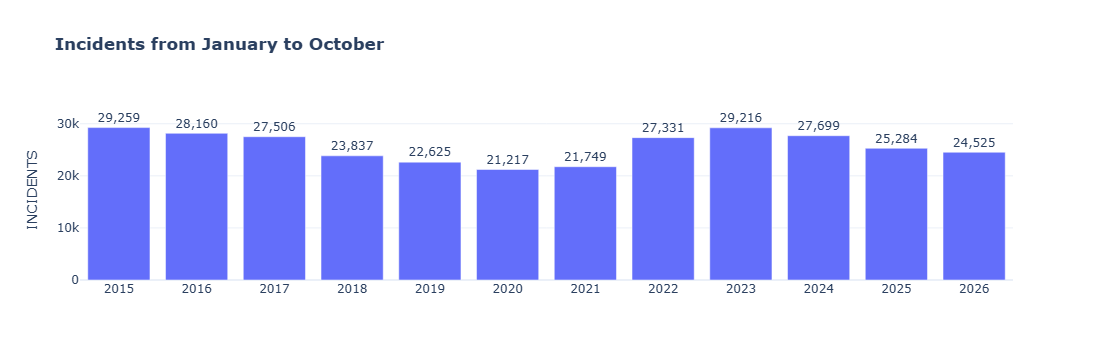

In [16]:
cut_year, cut_month = last_complete_month(df)
month_name = pd.Timestamp(year=cut_year, month=cut_month, day=1).strftime("%B")
print("Window used: January to {} of each year".format(month_name))

ytd = year_to_date(df, cut_month)
ytd_total = ytd.sum(axis=1).rename("INCIDENTS").reset_index()

fig = px.bar(ytd_total, x="YEAR", y="INCIDENTS", text="INCIDENTS",
             title="<b>Incidents from January to {}</b>".format(month_name))
fig.update_traces(texttemplate="%{text:,}", textposition="outside")
fig.update_xaxes(dtick=1, title=None)
fig.show()

In [17]:
latest = df["YEAR"].max()
table = pd.DataFrame({
    "vs {}".format(latest - 1): (ytd.loc[latest] / ytd.loc[latest - 1] - 1) * 100,
    "vs {}".format(BASE_YEAR): (ytd.loc[latest] / ytd.loc[BASE_YEAR] - 1) * 100,
}).round(1)
table.loc["All categories"] = [
    round((ytd.loc[latest].sum() / ytd.loc[latest - 1].sum() - 1) * 100, 1),
    round((ytd.loc[latest].sum() / ytd.loc[BASE_YEAR].sum() - 1) * 100, 1),
]
print("Change (%) of {} (January to {}) compared with the same months".format(latest, month_name))
table

Change (%) of 2026 (January to October) compared with the same months


,vs 2025,vs 2019
CATEGORY,,
Vehicle contents or parts theft,5.2,5.5
Burglary,-5.4,-7.4
Mischief,-6.7,-1.7
Vehicle theft,-7.1,50.7
Robbery,-0.5,19.6
Offenses causing death,-48.6,11.8
All categories,-3.0,8.4


## Key figures

In [18]:
total = yearly.sum(axis=1)
print("Lowest year: {} ({:,} incidents), highest year: {} ({:,} incidents)".format(
    total.idxmin(), total.min(), total.idxmax(), total.max()))
print("{} vs {}: {:+.1%} incidents overall".format(LAST_FULL_YEAR, BASE_YEAR,
      total[LAST_FULL_YEAR] / total[BASE_YEAR] - 1))
main = comparison.loc[MAIN_CATEGORIES].sort_values("Change (%)", ascending=False)
print("Main category furthest above its {} level in {}: {} ({:+.1f}%)".format(
    BASE_YEAR, LAST_FULL_YEAR, main.index[0], main["Change (%)"].iloc[0]))
print("Main category furthest below: {} ({:+.1f}%)".format(
    main.index[-1], main["Change (%)"].iloc[-1]))

Lowest year: 2020 (25,460 incidents), highest year: 2015 (35,609 incidents)
2025 vs 2019: +9.9% incidents overall
Main category furthest above its 2019 level in 2025: Vehicle theft (+57.8%)
Main category furthest below: Burglary (-4.7%)


## Conclusions

**1. Compared with 2019, 2025 is higher for vehicle theft (+57.8%) and robbery (+15.7%), roughly back to normal for mischief (+4.0%) and vehicle contents or parts theft (+0.7%), and lower for burglary (−4.7%).** Overall, 2025 has 29,832 incidents against 27,155 in 2019 (+9.9%). Offenses causing death rise from 24 to 39, but these are small numbers and should not be read as a trend.

**2. Vehicle theft started rising in 2020 (4,706 incidents), peaked in 2023 (11,528, +176% vs 2019, with August 2023 the busiest month), then fell to 8,661 in 2024 and 6,579 in 2025.** 2025 is still 58% above 2019. The time of day barely changed: about half of the thefts are reported during the day and 22–25% at night, every year.

**3. The largest increases are concentrated in a few grid cells in the east-centre of the island (top cell: 45.50, −73.56, PDQ 21; other cells under PDQ 20, 38 and 12) and in the west (45.46, −73.83, PDQ 5).** The top cell goes from 22 to 255 thefts between 2019 and 2023. Only incidents with a usable location are counted, so the real increase is larger.

**4. Weekdays: most crime types are highest on Monday and lowest on the weekend, except robbery, which is flat across the week (14–14.6% every day).** Vehicle theft is the exception to the weekend dip: it used to fall on Saturday and Sunday (11.4% and 10.2% of thefts in 2015–2019) but is now spread almost evenly over the week (13.3% and 14.3% in 2022–2025). Night: vehicle theft stays around 22–25% with no trend. Burglary and mischief become more night-time after 2019 (peaks of 22.4% in 2022 and 16.2% in 2023) and then ease slightly, while robbery drops from about 20% in 2019 to 16% in 2025. Crime as a whole has therefore not moved to the night.

**5. Incidents are slightly more concentrated than before.** The busiest 1% of locations account for 7.8% of incidents in 2019, 11.1% in 2023 and 9.8% in 2025 (busiest 5%: 21.9%, 26.6%, 25.5%). The rise coincides with the vehicle theft wave, but this calculation covers all categories, so it does not prove the link.

**6. From January to October, 2026 is 3.0% below 2025 but 8.4% above 2019.** Vehicle theft is down 7.1% against 2025 but still 50.7% above 2019. The decline since the 2023 peak therefore continues, without a return to the 2019 level.

## Limitations
* The data counts incidents **reported to the police**, not all crimes. A change in reporting habits can look like a change in crime.
* Incidents are shown without population or traffic data, so counts are not rates.
* About 17% of rows have no usable location; location analyses cover the rest only.
* Locations are moved to the nearest intersection, and PDQ boundaries changed during the period.
* The "date" is the date of the report, which may differ from the date of the event.